## Electronics Classification Using Transfer Learning

This project explores image classification using Python, TensorFlow, and Keras to identify electronic components from images. Using a publicly available electronic component dataset, It shows how to prepare image data, apply transfer learning with a pretrained convolutional neural network (MobileNetV2), train and evaluate a classification model, and understand the principles behind each step.

In [2]:
#LOCATE DATASET ON MY DISK
from pathlib import Path

dataset_path = Path(r"C:\Users\user\OneDrive\Desktop\End-to-end_ML_Projects\AI Industrial Electronics Classifier\ElectroCom61 A Multiclass Dataset for Detection of Electronic Components")

print('path exists?',dataset_path.exists())
print('path is a folder?', dataset_path.is_dir())

path exists? True
path is a folder? True


In [3]:
#read the top files in the folder
for item in sorted(dataset_path.iterdir()):
    kind = "FOLDER" if item.is_dir() else "FILE"
    print(f"{kind:7} {item.name}")

FOLDER  ElectroCom61
FILE    Metadata_ElectroCom61.csv


In [4]:
#digging deep the file
images_root = dataset_path / "ElectroCom61"

items = sorted(images_root.iterdir())
folders = [i for i in items if i.is_dir()]
files = [i for i in items if i.is_file()]

print("Total items:", len(items))
print("Folders:", len(folders))
print("Files:", len(files))

print("\nFirst 15 items:")
for item in items[:15]:
    kind = "FOLDER" if item.is_dir() else "FILE"
    print(f"{kind:7} {item.name}")

Total items: 6
Folders: 3
Files: 3

First 15 items:
FILE    data.yaml
FILE    README.dataset.txt
FILE    README.roboflow.txt
FOLDER  test
FOLDER  train
FOLDER  valid


In [5]:
#Read the dataset’s own description
for name in ["data.yaml", "README.dataset.txt", "README.roboflow.txt"]:
    print("=" * 20, name, "=" * 20)
    print((images_root / name).read_text(encoding="utf-8")[:2000])
    print()

==================== data.yaml ====================
train: ../train/images
val: ../valid/images
test: ../test/images

nc: 61
names: ['1-5-Volt-Battery', '3-3-Volt-Battery', '7-Segment-Display', '9-Volt-Battery', 'Arduino-Mega', 'Arduino-Nano', 'Arduino-Uno', 'BJT-Transistor', 'Bluetooth-Module', 'Breadboard', 'Bridge-Rectifier', 'Buck-Converter', 'Buzzer', 'Capacitor-10mf', 'Capacitor-470mf', 'DC-Motor', 'Diode', 'ESP32', 'ESP32-CAM', 'FT-232-USB-Serial-Module', 'Film-Capacitor', 'Fuse', 'Fuse-Base', 'GSM-Module', 'Gas-Sensor', 'Heat-Sink', 'High-Voltage-Ceramic-Capacitor', 'Humidity-Sensor', 'IC-Base-14-Pin', 'IC-Base-28-Pin', 'IC-Chip', 'IGBT', 'IR-Sensor', 'Inductor', 'Keypad', 'LCD-Display', 'LDR-Sensor', 'LED-Light', 'Low-Voltage-Ceramic-Capacitor', 'MLC-Capacitor', 'MOSFET', 'Motion-Sensor', 'Motor-Driver', 'NTC-Thermistor', 'OLED-Display', 'Pin-Header', 'Push-Switch', 'RFID-Scanner', 'Raindrops-Module', 'Relay-Module', 'Resistor', 'Rocker-Switch', 'Servo-Motor', 'Soil-Moisture-S

In [6]:
#check how the train image and label files are arranged and how many is inside
train_dir = images_root / "train"
print("Inside train:", [p.name for p in train_dir.iterdir()])

imgs = sorted((train_dir / "images").iterdir())
lbls = sorted((train_dir / "labels").iterdir())

print("Images:", len(imgs))
print("Label files:", len(lbls))
print("First 3 images:", [p.name for p in imgs[:3]])
print("First 3 labels:", [p.name for p in lbls[:3]])

Inside train: ['images', 'labels']
Images: 1454
Label files: 1454
First 3 images: ['IMG20240219113638_jpg.rf.ccc7798e93d0b231fc026cb6fc6d836a.jpg', 'IMG20240219113715_jpg.rf.d2b6c21ec259afce5e9622e6b4742314.jpg', 'IMG20240219113726_jpg.rf.faab8dfe47c0199df2befddbefe69c2b.jpg']
First 3 labels: ['IMG20240219113638_jpg.rf.ccc7798e93d0b231fc026cb6fc6d836a.txt', 'IMG20240219113715_jpg.rf.d2b6c21ec259afce5e9622e6b4742314.txt', 'IMG20240219113726_jpg.rf.faab8dfe47c0199df2befddbefe69c2b.txt']


In [7]:
#Read one label file
first_label = lbls[0]
print("File:", first_label.name)
print("Contents:")
print(first_label.read_text())

File: IMG20240219113638_jpg.rf.ccc7798e93d0b231fc026cb6fc6d836a.txt
Contents:
20 0.5546875 0.3125 0.090625 0.07109375
20 0.63203125 0.37578125 0.096875 0.0703125
24 0.4921875 0.4078125 0.13515625 0.07109375
42 0.47578125 0.4953125 0.1453125 0.1015625
39 0.375 0.35234375 0.025 0.03515625
39 0.38984375 0.38671875 0.04453125 0.02421875
39 0.59296875 0.50859375 0.040625 0.03125
36 0.67109375 0.44765625 0.09609375 0.03046875
39 0.41640625 0.653125 0.02578125 0.02421875
54 0.35546875 0.59296875 0.12890625 0.084375
54 0.48671875 0.6140625 0.11015625 0.08828125


Size (width, height): (640, 640)


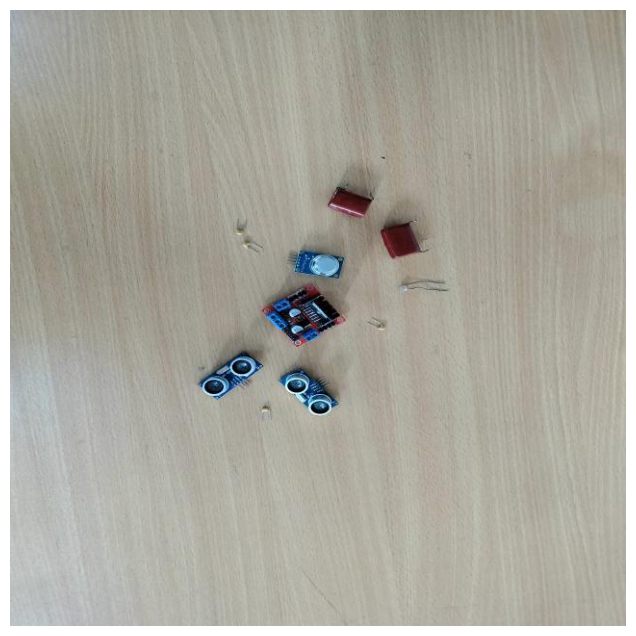

In [8]:
import matplotlib.pyplot as plt
from PIL import Image #--to open image

img = Image.open(imgs[0])
print("Size (width, height):", img.size)

plt.figure(figsize=(8, 8))
plt.imshow(img)
plt.axis("off")
plt.show()

In [9]:
# Count all images in one go

import yaml
from collections import Counter

with open(images_root / "data.yaml") as f:
    class_names = yaml.safe_load(f)["names"]

train_counts = Counter()

for split in ["train", "valid", "test"]:
    d = images_root / split
    n_img = len(list((d / "images").iterdir()))
    counts = Counter()
    for f in (d / "labels").glob("*.txt"):
        for line in f.read_text().splitlines():
            if line.strip():
                counts[int(line.split()[0])] += 1
    print(f"{split:6} images: {n_img:5}  objects: {sum(counts.values()):6}")
    if split == "train":
        train_counts = counts

print("\nMost common classes in train:")
for cid, n in train_counts.most_common(5):
    print(f"  {class_names[cid]:30} {n}")

print("\nLeast common classes in train:")
for cid, n in train_counts.most_common()[-5:]:
    print(f"  {class_names[cid]:30} {n}")

train  images:  1454  objects:   8877
valid  images:   412  objects:   2507
test   images:   205  objects:   1283

Most common classes in train:
  IC-Chip                        221
  MLC-Capacitor                  217
  LED-Light                      203
  OLED-Display                   196
  Inductor                       193

Least common classes in train:
  Buck-Converter                 115
  TCRT5000                       115
  LDR-Sensor                     114
  9-Volt-Battery                 107
  RFID-Scanner                   105


In [10]:
# Check for data leakage - if there are any similar data in train, validation and test set
import re
import numpy as np
from datetime import datetime

def get_stamp(path):
    m = re.match(r"IMG(\d{14})", path.name)
    return datetime.strptime(m.group(1), "%Y%m%d%H%M%S").timestamp() if m else None

stamps = {}
for split in ["train", "valid", "test"]:
    files = list((images_root / split / "images").iterdir())
    vals = [get_stamp(p) for p in files]
    stamps[split] = np.array([v for v in vals if v is not None])
    print(f"{split:6} parsed {len(stamps[split])} of {len(files)} filenames")

for split in ["valid", "test"]:
    gaps = np.array([np.abs(stamps["train"] - t).min() for t in stamps[split]])
    print(f"\n{split}: median gap to nearest train photo = {np.median(gaps):.0f} s")
    print(f"{split}: share within 60 s of a train photo = {np.mean(gaps <= 60):.0%}")

def base(p):
    return p.name.split("_jpg.rf.")[0]

names = {s: {base(p) for p in (images_root / s / "images").iterdir()}
         for s in ["train", "valid", "test"]}
print("\nSame original photo in train & valid:", len(names["train"] & names["valid"]))
print("Same original photo in train & test: ", len(names["train"] & names["test"]))

train  parsed 492 of 1454 filenames
valid  parsed 141 of 412 filenames
test   parsed 69 of 205 filenames

valid: median gap to nearest train photo = 8 s
valid: share within 60 s of a train photo = 99%

test: median gap to nearest train photo = 13 s
test: share within 60 s of a train photo = 100%

Same original photo in train & valid: 0
Same original photo in train & test:  0


In [11]:
train_files = sorted((images_root / "train" / "images").iterdir())
unmatched = [p.name for p in train_files if not p.name.startswith("IMG")]
print("Not starting with IMG:", len(unmatched))
for n in unmatched[:8]:
    print(n)

Not starting with IMG: 0


In [12]:
import re

pattern = re.compile(r"IMG(\d{14})")
unmatched = [p.name for p in train_files if not pattern.match(p.name)]

print("Names that fail the 14-digit pattern:", len(unmatched))
for n in unmatched[:8]:
    print(n)

Names that fail the 14-digit pattern: 962
IMG_20240219_113620_jpg.rf.823e7f3bbf6c75840e4c8143d5417d47.jpg
IMG_20240219_113626_jpg.rf.964e3426611b2dab872e9db55a1e0385.jpg
IMG_20240219_113631_jpg.rf.c5ba9f6dfd90b2571407aa3e4edbf483.jpg
IMG_20240219_113639_jpg.rf.11a9b8e0f409b57ad2fa22027e7689ed.jpg
IMG_20240219_113715_jpg.rf.556606f674c6e412aea8f95bf49b7d82.jpg
IMG_20240219_113719_jpg.rf.29e98e591de13b2e5a4a655c1bcca23c.jpg
IMG_20240219_113739_jpg.rf.bff0f66805be02b019fe6972b70e2ae1.jpg
IMG_20240219_113808_jpg.rf.9b2a5fe60ce6f7e5967c53f6563892fe.jpg


In [13]:
# Redo the leakage test
import re
import numpy as np
from datetime import datetime

pat = re.compile(r"IMG_?(\d{8})_?(\d{6})")

def get_stamp(p):
    m = pat.match(p.name)
    return datetime.strptime(m.group(1) + m.group(2), "%Y%m%d%H%M%S").timestamp() if m else None

stamps = {}
for split in ["train", "valid", "test"]:
    files = list((images_root / split / "images").iterdir())
    vals = [get_stamp(p) for p in files]
    stamps[split] = np.array([v for v in vals if v is not None])
    print(f"{split:6} parsed {len(stamps[split])} of {len(files)}")

for split in ["valid", "test"]:
    gaps = np.array([np.abs(stamps["train"] - t).min() for t in stamps[split]])
    print(f"{split}: median gap to nearest train photo = {np.median(gaps):.0f} s, "
          f"within 60 s = {np.mean(gaps <= 60):.0%}")

all_t = np.sort(np.concatenate(list(stamps.values())))
n_sessions = int((np.diff(all_t) > 60).sum()) + 1
print("\nTotal photos:", len(all_t))
print("Sessions (gap > 60 s starts a new one):", n_sessions)

train  parsed 1321 of 1454
valid  parsed 376 of 412
test   parsed 185 of 205
valid: median gap to nearest train photo = 5 s, within 60 s = 100%
test: median gap to nearest train photo = 4 s, within 60 s = 100%

Total photos: 1882
Sessions (gap > 60 s starts a new one): 51


In [14]:
unparsed = []
for split in ["train", "valid", "test"]:
    for p in (images_root / split / "images").iterdir():
        if get_stamp(p) is None:
            unparsed.append(p.name)

print("Unparsed total:", len(unparsed))
for n in sorted(unparsed)[:10]:
    print(n)

Unparsed total: 189
IMG_5126_JPG.rf.a864f0f22819f352492ed7958a05b40a.jpg
IMG_5127_JPG.rf.9883db6565cbabcb507296014a63e0a4.jpg
IMG_5128_JPG.rf.943c597ba562874a1bb3d26fe130cbda.jpg
IMG_5129_JPG.rf.24311d4332dd4fe23b28b7327fd9c251.jpg
IMG_5130_JPG.rf.094ecd60935c58493b2c26bab78a4d0a.jpg
IMG_5131_JPG.rf.d263f1741a735898d9ab6d0d687723eb.jpg
IMG_5132_JPG.rf.7b377862d5c7a7ad7ab70858528ebdb0.jpg
IMG_5133_JPG.rf.3980e14b73240ec2d7224edebb163232.jpg
IMG_5134_JPG.rf.68929d9d88c840596545da738c74c0d5.jpg
IMG_5135_JPG.rf.06701964b0927d10df0107c4bd63dffc.jpg


In [16]:
import re             
import numpy as np     

# Pattern for names like "IMG_5126_JPG.rf...."
# \d+ means "one or more digits"; the parentheses capture those digits
# re.IGNORECASE lets it match both "_JPG" and "_jpg"
seq_pat = re.compile(r"IMG_(\d+)_JPG", re.IGNORECASE)

# Collect the camera sequence number from each unparsed filename
seq = []
for name in unparsed:               # 'unparsed' = the 189 names from last step
    m = seq_pat.match(name)         # try the pattern on this filename
    if m:                           # m is None if the name doesn't fit
        seq.append(int(m.group(1))) # group(1) = the digits; int() makes it a number

# Sort so neighboring numbers are neighboring shots
seq = np.sort(np.array(seq))
print("Parsed:", len(seq), "of", len(unparsed))   # should be 189 of 189
print("Range:", seq.min(), "to", seq.max())       # lowest and highest number

# Difference between each number and the next: 5126 -> 5127 gives 1
jumps = np.diff(seq)

# A jump bigger than 5 means several shots are missing between two photos,
# so we assume a new shooting group started there (our guess, not a fact)
print("Gaps larger than 5 (new group):", int((jumps > 5).sum()))
print("Number of groups:", int((jumps > 5).sum()) + 1)  # N boundaries = N+1 groups

# The 5 biggest jumps, to check whether a cutoff of 5 sits in a natural gap
print("Largest jumps:", sorted(jumps.tolist())[-5:])

Parsed: 189 of 189
Range: 5126 to 5323
Gaps larger than 5 (new group): 1
Number of groups: 2
Largest jumps: [1, 1, 1, 1, 10]


In [18]:
import re, random
from collections import Counter
from datetime import datetime

# Two filename styles: timestamped (IMG_20240219_113620 / IMG20240219113638)
# and camera sequence number (IMG_5126_JPG)
ts_pat = re.compile(r"IMG_?(\d{8})_?(\d{6})")
seq_pat = re.compile(r"IMG_(\d+)_JPG", re.IGNORECASE)

# 1) List every photo from the three original folders, one dictionary per photo
records = []
for split in ["train", "valid", "test"]:
    for p in (images_root / split / "images").iterdir():
        m = ts_pat.match(p.name)
        if m:   # timestamped: convert date+time into seconds
            t = datetime.strptime(m.group(1) + m.group(2), "%Y%m%d%H%M%S").timestamp()
            records.append({"path": p, "kind": "time", "value": t})
        else:
            m2 = seq_pat.match(p.name)
            if m2:  # sequence number
                records.append({"path": p, "kind": "seq", "value": int(m2.group(1))})
            else:   # fits neither pattern
                records.append({"path": p, "kind": "none", "value": None})

# 2) Sort each kind by value and start a new group at every big jump
#    (more than 60 s apart for timestamps, more than 5 numbers apart for sequences)
for kind, gap in [("time", 60), ("seq", 5)]:
    subset = sorted([r for r in records if r["kind"] == kind], key=lambda r: r["value"])
    gid = 0
    for i, r in enumerate(subset):
        if i > 0 and r["value"] - subset[i - 1]["value"] > gap:
            gid += 1
        r["group"] = f"{kind}-{gid}"

print("Total photos:", len(records))
print("Without a group:", sum(1 for r in records if "group" not in r))

# 3) Collect photos by group so each group stays together
groups = {}
for r in records:
    if "group" in r:
        groups.setdefault(r["group"], []).append(r)
print("Number of groups:", len(groups))

# 4) Shuffle the group names (fixed seed 42 = same split every run)
ids = sorted(groups)
random.Random(42).shuffle(ids)

# 5) Deal whole groups: first ~70% of photos to train, next ~15% to val, rest to test
grouped_total = sum(len(v) for v in groups.values())
seen = 0
for g in ids:
    frac = seen / grouped_total
    split = "train" if frac < 0.70 else "val" if frac < 0.85 else "test"
    for r in groups[g]:
        r["split"] = split
    seen += len(groups[g])

print(Counter(r["split"] for r in records if "split" in r))

Total photos: 2071
Without a group: 0
Number of groups: 53
Counter({'train': 1494, 'test': 299, 'val': 278})


In [19]:
from collections import Counter

# Count objects per class in each split, reading each photo's YOLO label file
counts = {"train": Counter(), "val": Counter(), "test": Counter()}

for r in records:
    # Label file has the same name as the image, but in "labels" and ending .txt
    label_file = r["path"].parent.parent / "labels" / (r["path"].stem + ".txt")
    for line in label_file.read_text().splitlines():
        if line.strip():
            class_id = int(line.split()[0])    # first number = class id
            counts[r["split"]][class_id] += 1  # tally it in this photo's split

# For each class, find its smallest count across the three splits
rows = []
for cid in range(len(class_names)):            # class_names is from data.yaml
    tr, va, te = counts["train"][cid], counts["val"][cid], counts["test"][cid]
    rows.append((min(tr, va, te), class_names[cid], tr, va, te))

# Show the 10 classes whose weakest split is smallest
rows.sort()
print(f"{'class':30} {'train':>6} {'val':>6} {'test':>6}")
for _, name, tr, va, te in rows[:10]:
    print(f"{name:30} {tr:6} {va:6} {te:6}")

class                           train    val   test
3-3-Volt-Battery                  181     24      0
7-Segment-Display                 149     16      0
9-Volt-Battery                    111      0     49
Arduino-Mega                      158     10      0
Arduino-Uno                         0      0    193
Bluetooth-Module                  188     61      0
Breadboard                        152     11      0
Buck-Converter                    147     16      0
Buzzer                            166      0    106
DC-Motor                          166      5      0


In [20]:
from PIL import Image
from pathlib import Path
from collections import Counter

# 1) Count objects per class in each split (same logic as before, just internal now)
counts = {"train": Counter(), "val": Counter(), "test": Counter()}
for r in records:
    label_file = r["path"].parent.parent / "labels" / (r["path"].stem + ".txt")
    for line in label_file.read_text().splitlines():
        if line.strip():
            counts[r["split"]][int(line.split()[0])] += 1

# 2) Pick the 10 classes whose smallest split is largest
#    (so every chosen class has enough examples in train, val AND test)
ranked = sorted(range(len(class_names)),
                key=lambda c: min(counts["train"][c], counts["val"][c], counts["test"][c]),
                reverse=True)
chosen = ranked[:10]
print("Chosen classes:", [class_names[c] for c in chosen])

# 3) Crop every box of a chosen class and save it as its own small image
#    Folder layout: crops/<split>/<class name>/<file>.jpg
out_root = Path("crops")
saved = Counter()

for r in records:
    label_file = r["path"].parent.parent / "labels" / (r["path"].stem + ".txt")
    img = Image.open(r["path"]).convert("RGB")
    W, H = img.size

    for i, line in enumerate(label_file.read_text().splitlines()):
        if not line.strip():
            continue
        cid, xc, yc, w, h = line.split()
        cid = int(cid)
        if cid not in chosen:                      # skip classes we aren't using
            continue

        # YOLO fractions -> pixel corners, with 10% padding around the box
        xc, yc, w, h = float(xc) * W, float(yc) * H, float(w) * W, float(h) * H
        pad_w, pad_h = w * 0.1, h * 0.1
        left   = max(0, xc - w / 2 - pad_w)
        top    = max(0, yc - h / 2 - pad_h)
        right  = min(W, xc + w / 2 + pad_w)
        bottom = min(H, yc + h / 2 + pad_h)

        if right - left < 20 or bottom - top < 20:  # skip tiny, unusable crops
            continue

        folder = out_root / r["split"] / class_names[cid]
        folder.mkdir(parents=True, exist_ok=True)
        img.crop((left, top, right, bottom)).save(folder / f"{r['path'].stem}_{i}.jpg")
        saved[r["split"]] += 1

print("Crops saved:", dict(saved))

Chosen classes: ['IC-Base-28-Pin', 'IC-Base-14-Pin', 'GSM-Module', 'Humidity-Sensor', 'Motion-Sensor', 'Water-Sensor', 'Relay-Module', 'Trimmer-Potentiometer', 'Sonar-Sensor', 'Bridge-Rectifier']
Crops saved: {'val': 507, 'train': 1196, 'test': 617}


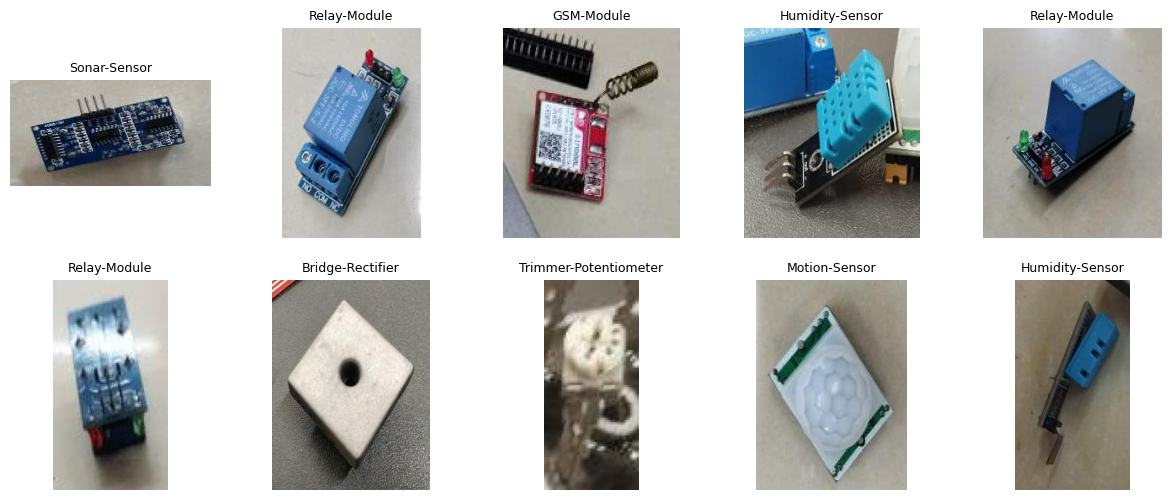

In [21]:
import random
import matplotlib.pyplot as plt
from PIL import Image
from pathlib import Path

# Collect every crop in the training folder
all_crops = list(Path("crops/train").glob("*/*.jpg"))

# Pick 10 at random and show each with its class (the folder name)
fig, axes = plt.subplots(2, 5, figsize=(15, 6))
for ax, p in zip(axes.flat, random.sample(all_crops, 10)):
    ax.imshow(Image.open(p))
    ax.set_title(p.parent.name, fontsize=9)   # folder name = class label
    ax.axis("off")
plt.show()

In [22]:
import tensorflow as tf

IMG_SIZE = (224, 224)   # every crop is resized to this width x height
BATCH = 32              # images processed per weight update

# Each folder name under crops/<split>/ becomes a class label
# shuffle=True mixes training order each epoch; for val/test we keep a fixed order
train_ds = tf.keras.utils.image_dataset_from_directory(
    "crops/train", image_size=IMG_SIZE, batch_size=BATCH, shuffle=True, seed=42)
val_ds = tf.keras.utils.image_dataset_from_directory(
    "crops/val", image_size=IMG_SIZE, batch_size=BATCH, shuffle=False)
test_ds = tf.keras.utils.image_dataset_from_directory(
    "crops/test", image_size=IMG_SIZE, batch_size=BATCH, shuffle=False)

# Keras sorts class folders alphabetically, then numbers them 0 to 9
# (a new variable name, so we don't overwrite the 61-class list from data.yaml)
ds_class_names = train_ds.class_names
print("Classes:", ds_class_names)

# Look at one batch to see the shapes
for images, labels in train_ds.take(1):
    print("Image batch shape:", images.shape)
    print("Label batch shape:", labels.shape)

C:\Users\user\anaconda3\Lib\site-packages\pandas\core\computation\expressions.py:22: UserWarning: Pandas requires version '2.10.2' or newer of 'numexpr' (version '2.10.1' currently installed).
  from pandas.core.computation.check import NUMEXPR_INSTALLED


Found 1196 files belonging to 10 classes.
Found 507 files belonging to 10 classes.
Found 617 files belonging to 10 classes.
Classes: ['Bridge-Rectifier', 'GSM-Module', 'Humidity-Sensor', 'IC-Base-14-Pin', 'IC-Base-28-Pin', 'Motion-Sensor', 'Relay-Module', 'Sonar-Sensor', 'Trimmer-Potentiometer', 'Water-Sensor']
Image batch shape: (32, 224, 224, 3)
Label batch shape: (32,)


## Transfer Learning with MobileNetV2

In [23]:
# Load MobileNetV2 with its ImageNet knowledge (weights="imagenet"),
# without the final 1000-class layer (include_top=False)
base_model = tf.keras.applications.MobileNetV2(
    input_shape=(224, 224, 3),   # must match our image size
    include_top=False,
    weights="imagenet")          # downloads the weights the first time

base_model.trainable = False     # freeze: training will not change these layers

print("Number of layers:", len(base_model.layers))

# Pass one batch of our images through it and look at what comes out
for images, labels in train_ds.take(1):
    features = base_model(images)
    print("Output shape:", features.shape)

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 452s 48us/step
Number of layers: 154
Output shape: (32, 7, 7, 1280)


## build the model

In [24]:
# 1) Input: a batch of 224x224 color images
inputs = tf.keras.Input(shape=(224, 224, 3))

# 2) MobileNetV2 expects pixel values between -1 and 1, not 0 to 255
x = tf.keras.applications.mobilenet_v2.preprocess_input(inputs)

# 3) Pass the images through the frozen base (its output is the 7x7x1280 you just saw)
#    training=False keeps the base's batch-normalization layers in "use what you learned" mode
x = base_model(x, training=False)

# 4) Average the 7x7 grid for each channel: (32, 7, 7, 1280) becomes (32, 1280)
x = tf.keras.layers.GlobalAveragePooling2D()(x)

# 5) New head: 1280 numbers in, 10 class probabilities out
outputs = tf.keras.layers.Dense(10, activation="softmax")(x)

# 6) Wrap everything from inputs to outputs into one model
model = tf.keras.Model(inputs, outputs)

model.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ true_divide (TrueDivide)        │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ subtract (Subtract)             │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 10)             │        12,810 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,270,794 (8.66 MB)

 Trainable params: 12,810 (50.04 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

In [25]:
# compile and fit the model
# Configure learning: how to measure error, how to adjust, what to report
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),  # step size = 0.001
    loss="sparse_categorical_crossentropy",                   # error measure for integer labels
    metrics=["accuracy"])                                     # share of correct predictions

# Train for 5 epochs; validation data is only scored, never learned from
history = model.fit(train_ds, validation_data=val_ds, epochs=5)

Epoch 1/5


C:\Users\user\anaconda3\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


38/38 ━━━━━━━━━━━━━━━━━━━━ 44s 1s/step - accuracy: 0.6396 - loss: 1.2843 - val_accuracy: 0.8659 - val_loss: 0.6088
Epoch 2/5
38/38 ━━━━━━━━━━━━━━━━━━━━ 34s 898ms/step - accuracy: 0.9239 - loss: 0.3678 - val_accuracy: 0.9290 - val_loss: 0.3818
Epoch 3/5
38/38 ━━━━━━━━━━━━━━━━━━━━ 36s 964ms/step - accuracy: 0.9649 - loss: 0.2159 - val_accuracy: 0.9428 - val_loss: 0.3152
Epoch 4/5
38/38 ━━━━━━━━━━━━━━━━━━━━ 35s 920ms/step - accuracy: 0.9799 - loss: 0.1458 - val_accuracy: 0.9467 - val_loss: 0.2819
Epoch 5/5
38/38 ━━━━━━━━━━━━━━━━━━━━ 36s 942ms/step - accuracy: 0.9900 - loss: 0.1070 - val_accuracy: 0.9487 - val_loss: 0.2556


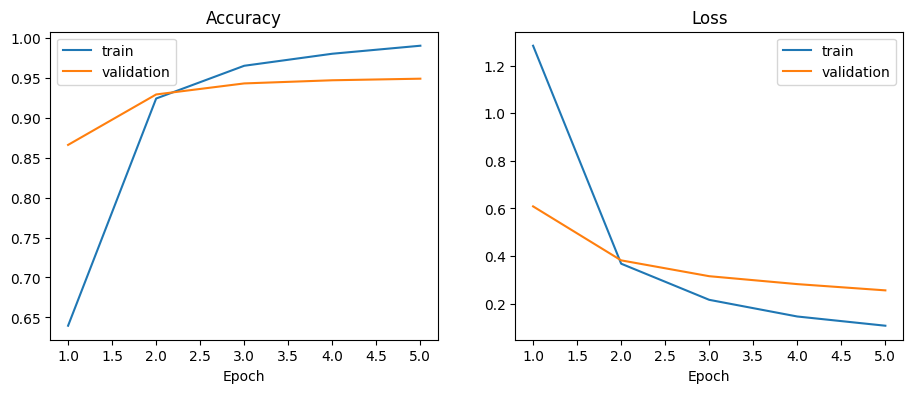

In [27]:
import matplotlib.pyplot as plt

h = history.history                        # dictionary of per-epoch results
epochs = range(1, len(h["accuracy"]) + 1)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4))

ax1.plot(epochs, h["accuracy"], label="train")
ax1.plot(epochs, h["val_accuracy"], label="validation")
ax1.set_title("Accuracy"); ax1.set_xlabel("Epoch"); ax1.legend()

ax2.plot(epochs, h["loss"], label="train")
ax2.plot(epochs, h["val_loss"], label="validation")
ax2.set_title("Loss"); ax2.set_xlabel("Epoch"); ax2.legend()

plt.show()

16/16 ━━━━━━━━━━━━━━━━━━━━ 14s 792ms/step
                       precision    recall  f1-score   support

     Bridge-Rectifier       0.90      0.98      0.94        46
           GSM-Module       0.98      1.00      0.99        50
      Humidity-Sensor       0.96      1.00      0.98        50
       IC-Base-14-Pin       0.92      0.89      0.90        53
       IC-Base-28-Pin       0.96      0.93      0.94        54
        Motion-Sensor       0.92      0.88      0.90        50
         Relay-Module       0.94      1.00      0.97        48
         Sonar-Sensor       0.98      0.88      0.93        59
Trimmer-Potentiometer       0.92      1.00      0.96        48
         Water-Sensor       1.00      0.96      0.98        49

             accuracy                           0.95       507
            macro avg       0.95      0.95      0.95       507
         weighted avg       0.95      0.95      0.95       507



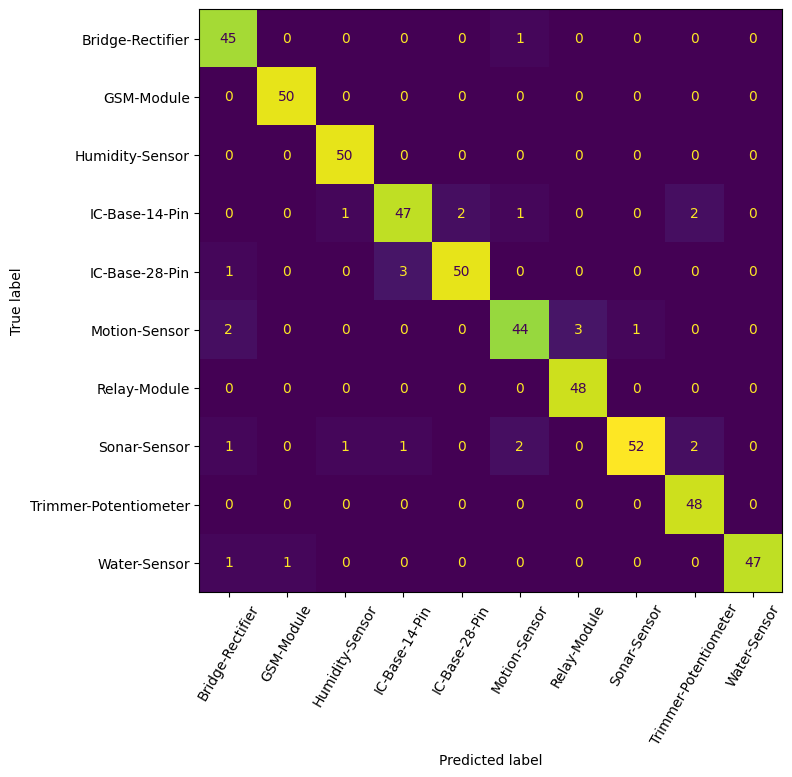

In [28]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, classification_report, ConfusionMatrixDisplay

# True labels: collect them from the validation dataset
# (val_ds was loaded with shuffle=False, so the order matches the predictions)
y_true = np.concatenate([labels.numpy() for images, labels in val_ds])

# Predictions: the model returns 10 probabilities per crop; argmax picks the highest
probs = model.predict(val_ds)
y_pred = np.argmax(probs, axis=1)

# Per-class precision, recall and F1 (plain text table)
print(classification_report(y_true, y_pred, target_names=ds_class_names))

# Confusion matrix as a picture: rows = true class, columns = predicted class
cm = confusion_matrix(y_true, y_pred)
fig, ax = plt.subplots(figsize=(8, 8))
ConfusionMatrixDisplay(cm, display_labels=ds_class_names).plot(
    ax=ax, xticks_rotation=60, colorbar=False)
plt.tight_layout()
plt.show()

In [29]:
# cm is the confusion matrix from the last cell: rows = true class, columns = predicted
mistakes = []
for i in range(len(ds_class_names)):
    for j in range(len(ds_class_names)):
        if i != j and cm[i, j] > 0:                      # off the diagonal = errors
            mistakes.append((cm[i, j], ds_class_names[i], ds_class_names[j]))

# Show the 6 most frequent confusions, largest first
for count, true_c, pred_c in sorted(mistakes, reverse=True)[:6]:
    print(f"{count:3} x  true {true_c:22} -> predicted {pred_c}")

  3 x  true Motion-Sensor          -> predicted Relay-Module
  3 x  true IC-Base-28-Pin         -> predicted IC-Base-14-Pin
  2 x  true Sonar-Sensor           -> predicted Trimmer-Potentiometer
  2 x  true Sonar-Sensor           -> predicted Motion-Sensor
  2 x  true Motion-Sensor          -> predicted Bridge-Rectifier
  2 x  true IC-Base-14-Pin         -> predicted Trimmer-Potentiometer


Total mistakes: 26


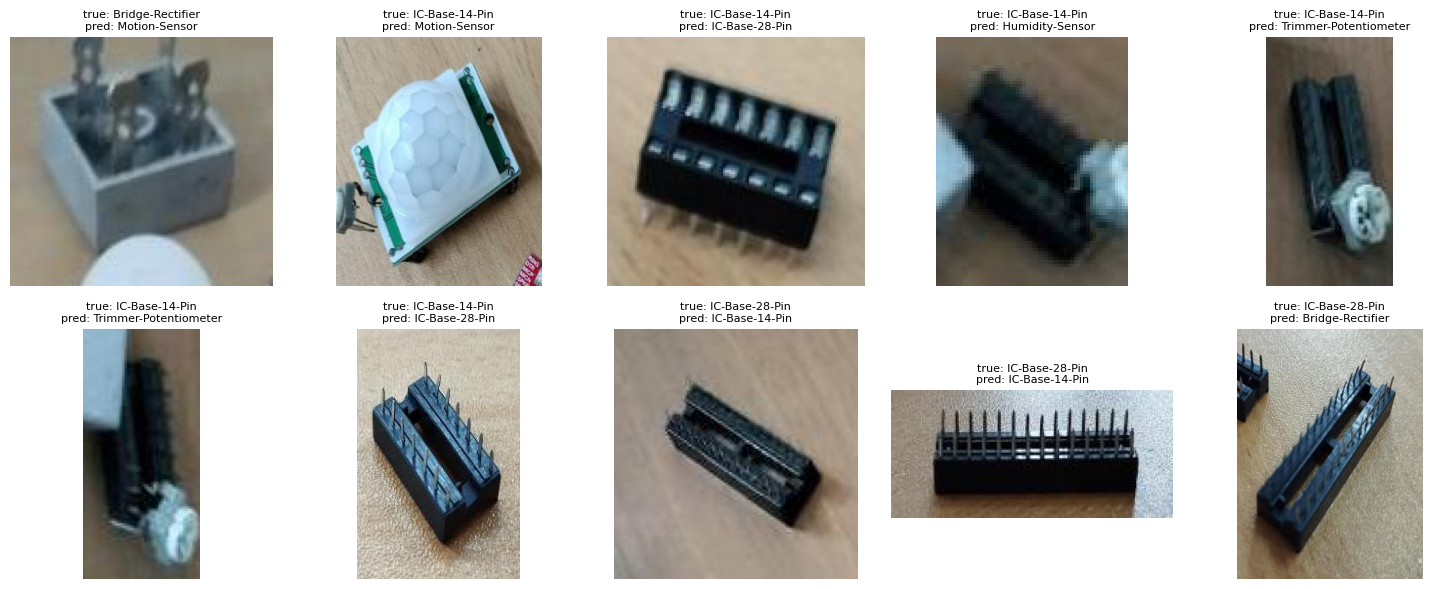

In [30]:
import matplotlib.pyplot as plt
from PIL import Image

# File paths of the validation crops, in the same order as y_true / y_pred
# (val_ds was loaded with shuffle=False, so the order matches)
paths = val_ds.file_paths

# Indexes of every crop the model got wrong
wrong = np.where(y_true != y_pred)[0]
print("Total mistakes:", len(wrong))

# Show the first 10 mistakes with true label and predicted label
fig, axes = plt.subplots(2, 5, figsize=(15, 6))
for ax, idx in zip(axes.flat, wrong[:10]):
    ax.imshow(Image.open(paths[idx]))
    ax.set_title(f"true: {ds_class_names[y_true[idx]]}\npred: {ds_class_names[y_pred[idx]]}",
                 fontsize=8)
    ax.axis("off")
plt.tight_layout()
plt.show()

## Fine Tune model

### Unfreeze the last layers and retrain gently at a very low learning rate 

Why the late layers only. The base learned features in a hierarchy. Early layers detect basic things like edges and color blobs, which are useful in every image. Late layers combine those into more specific patterns, and those are the ones worth adjusting to electronic components. So we unfreeze the last 30 of the 154 layers and keep the first 124 frozen.

In [31]:
# Our baseline from the frozen model, to compare against later:
# val_accuracy 0.9487, val_loss 0.2556 (after epoch 5)

# 1) Make the base trainable again (this unfreezes ALL 154 layers)
base_model.trainable = True

# 2) Re-freeze everything except the last 30 layers
fine_tune_from = len(base_model.layers) - 30
for layer in base_model.layers[:fine_tune_from]:
    layer.trainable = False

# 3) Check what is trainable now
n_trainable = int(sum(np.prod(w.shape) for w in model.trainable_weights))
print("Trainable parameters now:", n_trainable)

# 4) Recompile with a MUCH smaller learning rate (0.00001 instead of 0.001)
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-5),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"])

# 5) Train 5 more epochs; keep this history separate from the first one
history_ft = model.fit(train_ds, validation_data=val_ds, epochs=5)

Trainable parameters now: 1539210
Epoch 1/5


C:\Users\user\anaconda3\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


38/38 ━━━━━━━━━━━━━━━━━━━━ 55s 1s/step - accuracy: 0.8963 - loss: 0.3839 - val_accuracy: 0.9546 - val_loss: 0.2339
Epoch 2/5
38/38 ━━━━━━━━━━━━━━━━━━━━ 45s 1s/step - accuracy: 0.9515 - loss: 0.2367 - val_accuracy: 0.9546 - val_loss: 0.2220
Epoch 3/5
38/38 ━━━━━━━━━━━━━━━━━━━━ 47s 1s/step - accuracy: 0.9741 - loss: 0.1646 - val_accuracy: 0.9527 - val_loss: 0.2130
Epoch 4/5
38/38 ━━━━━━━━━━━━━━━━━━━━ 43s 1s/step - accuracy: 0.9883 - loss: 0.1216 - val_accuracy: 0.9507 - val_loss: 0.2059
Epoch 5/5
38/38 ━━━━━━━━━━━━━━━━━━━━ 43s 1s/step - accuracy: 0.9925 - loss: 0.0918 - val_accuracy: 0.9507 - val_loss: 0.1994


In [32]:
# score on test set
import numpy as np
from sklearn.metrics import classification_report

# True labels from the test set (test_ds was loaded with shuffle=False, so order matches)
y_test = np.concatenate([labels.numpy() for images, labels in test_ds])

# Predictions: 10 probabilities per crop, argmax picks the most likely class
probs_test = model.predict(test_ds)
y_pred_test = np.argmax(probs_test, axis=1)

# Overall accuracy, then the per-class table
print("Test accuracy:", np.mean(y_test == y_pred_test))
print(classification_report(y_test, y_pred_test, target_names=ds_class_names))


20/20 ━━━━━━━━━━━━━━━━━━━━ 19s 857ms/step
Test accuracy: 0.93354943273906
                       precision    recall  f1-score   support

     Bridge-Rectifier       1.00      0.90      0.95        63
           GSM-Module       1.00      0.95      0.98        64
      Humidity-Sensor       0.97      0.91      0.94        64
       IC-Base-14-Pin       0.89      0.82      0.86        62
       IC-Base-28-Pin       0.79      0.90      0.84        63
        Motion-Sensor       0.97      0.94      0.95        64
         Relay-Module       0.83      0.98      0.90        60
         Sonar-Sensor       0.96      1.00      0.98        47
Trimmer-Potentiometer       0.98      0.97      0.98        67
         Water-Sensor       0.98      0.97      0.98        63

             accuracy                           0.93       617
            macro avg       0.94      0.94      0.93       617
         weighted avg       0.94      0.93      0.93       617



In [33]:
from sklearn.metrics import confusion_matrix

# Rows = true class, columns = predicted class, on the TEST set
cm_test = confusion_matrix(y_test, y_pred_test)

mistakes = []
for i in range(len(ds_class_names)):
    for j in range(len(ds_class_names)):
        if i != j and cm_test[i, j] > 0:          # off the diagonal = errors
            mistakes.append((cm_test[i, j], ds_class_names[i], ds_class_names[j]))

# The 6 most frequent confusions, largest first
for count, true_c, pred_c in sorted(mistakes, reverse=True)[:6]:
    print(f"{count:3} x  true {true_c:22} -> predicted {pred_c}")

  9 x  true IC-Base-14-Pin         -> predicted IC-Base-28-Pin
  5 x  true IC-Base-28-Pin         -> predicted IC-Base-14-Pin
  5 x  true Humidity-Sensor        -> predicted Relay-Module
  4 x  true Bridge-Rectifier       -> predicted IC-Base-28-Pin
  2 x  true Motion-Sensor          -> predicted Relay-Module
  1 x  true Water-Sensor           -> predicted Relay-Module


## save the model

In [34]:
# Save the whole model: structure + trained weights, in one file
model.save("component_classifier.keras")

# Save the class names too, since the file stores class numbers (0-9) but not their names
import json
with open("class_names.json", "w") as f:
    json.dump(ds_class_names, f)

# Reload and check it behaves identically to the model in memory
reloaded = tf.keras.models.load_model("component_classifier.keras")
probs_reloaded = reloaded.predict(test_ds)
print("Same predictions as before:", np.allclose(probs_test, probs_reloaded, atol=1e-5))

20/20 ━━━━━━━━━━━━━━━━━━━━ 17s 766ms/step
Same predictions as before: True


## predict on a single image

In [35]:
import json
import numpy as np
import tensorflow as tf
from PIL import Image

# Load the saved model and the class names (the names are what turn "class 6" into "Relay-Module")
model_loaded = tf.keras.models.load_model("component_classifier.keras")
with open("class_names.json") as f:
    names = json.load(f)

def predict_image(path, top_k=3):
    # 1) Open the image and resize it to the size the model was trained on
    img = Image.open(path).convert("RGB").resize((224, 224))

    # 2) Turn it into a float array and add a batch dimension: (224,224,3) -> (1,224,224,3)
    batch = np.expand_dims(np.array(img, dtype="float32"), axis=0)

    # 3) The model returns 10 probabilities for the one image
    probs = model_loaded.predict(batch, verbose=0)[0]

    # 4) Sort from highest to lowest and keep the top few
    best = np.argsort(probs)[::-1][:top_k]
    return [(names[i], float(probs[i])) for i in best]

# Try it on one crop from the test set
test_path = test_ds.file_paths[0]
print("File:", test_path)
for name, p in predict_image(test_path):
    print(f"  {name:22} {p:.1%}")

File: crops/test\Bridge-Rectifier\IMG20240309112450_jpg.rf.03550a0c406982ee73fe0e8d4851f746_8.jpg
  Bridge-Rectifier       90.6%
  Humidity-Sensor        2.4%
  Sonar-Sensor           2.0%


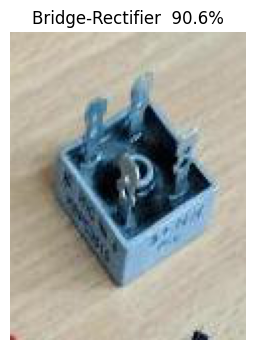

  Bridge-Rectifier       90.6%
  Humidity-Sensor        2.4%
  Sonar-Sensor           2.0%


In [36]:
import matplotlib.pyplot as plt
from PIL import Image

def show_prediction(path):
    # Run the model on this image (predict_image is the function from the last cell)
    results = predict_image(path)
    top_name, top_prob = results[0]          # best guess and its probability

    # Draw the image with the top guess as the title
    plt.figure(figsize=(4, 4))
    plt.imshow(Image.open(path))
    plt.title(f"{top_name}  {top_prob:.1%}")
    plt.axis("off")
    plt.show()

    # Also print the top 3
    for name, p in results:
        print(f"  {name:22} {p:.1%}")

show_prediction(test_path)

## add ui/ux

In [38]:
!pip install gradio

  Using cached uvicorn-0.54.0-py3-none-any.whl.metadata (6.6 kB)
  Using cached annotated_doc-0.0.5-py3-none-any.whl.metadata (6.5 kB)
   ---------------------------------------- 0.0/31.4 MB ? eta -:--:--
   ---------------------------------------- 0.0/31.4 MB ? eta -:--:--
   ---------------------------------------- 0.3/31.4 MB ? eta -:--:--
   - -------------------------------------- 0.8/31.4 MB 2.1 MB/s eta 0:00:15
   -- ------------------------------------- 2.1/31.4 MB 3.7 MB/s eta 0:00:08
   --- ------------------------------------ 2.9/31.4 MB 3.9 MB/s eta 0:00:08
   ---- ----------------------------------- 3.7/31.4 MB 4.1 MB/s eta 0:00:07
   ---- ----------------------------------- 3.7/31.4 MB 4.1 MB/s eta 0:00:07
   ------- -------------------------------- 5.5/31.4 MB 3.9 MB/s eta 0:00:07
   -------- ------------------------------- 6.3/31.4 MB 3.8 MB/s eta 0:00:07
   --------- ------------------------------ 7.6/31.4 MB 4.1 MB/s eta 0:00:06
   ----------- ------------------------

In [39]:

import gradio as gr
from PIL import Image
import numpy as np

def classify(image):
    # Gradio hands us the uploaded image as a numpy array (or None if nothing was uploaded)
    if image is None:
        return {}

    # Save it to a temporary file so we can reuse predict_image(path) unchanged
    Image.fromarray(image).convert("RGB").save("_upload.jpg")

    # Run the same function as before, asking for all 10 classes
    results = predict_image("_upload.jpg", top_k=10)

    # Gradio's Label output wants {class name: probability}
    return {name: p for name, p in results}

demo = gr.Interface(
    fn=classify,                                # the function to call on each upload
    inputs=gr.Image(),                          # an image upload box
    outputs=gr.Label(num_top_classes=3),        # shows the top 3 with confidence bars
    title="Electronic component classifier",
    description="Upload a cropped photo of ONE component from the 10 trained classes.")

demo.launch()

* Running on local URL:  http://127.0.0.1:7860
* To create a public link, set `share=True` in `launch()`.


Created dataset file at: .gradio\flagged\dataset1.csv
